In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# EDA

In [3]:
df = pd.read_csv('flights.csv')
df.head()

,id,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,...,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour,name
0,0,2013,1,1,517.0,515,2.0,830.0,819,11.0,...,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00,United Air Lines Inc.
1,1,2013,1,1,533.0,529,4.0,850.0,830,20.0,...,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01 05:00:00,United Air Lines Inc.
2,2,2013,1,1,542.0,540,2.0,923.0,850,33.0,...,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01 05:00:00,American Airlines Inc.
3,3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,...,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01 05:00:00,JetBlue Airways
4,4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,...,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01 06:00:00,Delta Air Lines Inc.


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 336776 entries, 0 to 336775
Data columns (total 21 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              336776 non-null  int64  
 1   year            336776 non-null  int64  
 2   month           336776 non-null  int64  
 3   day             336776 non-null  int64  
 4   dep_time        328521 non-null  float64
 5   sched_dep_time  336776 non-null  int64  
 6   dep_delay       328521 non-null  float64
 7   arr_time        328063 non-null  float64
 8   sched_arr_time  336776 non-null  int64  
 9   arr_delay       327346 non-null  float64
 10  carrier         336776 non-null  str    
 11  flight          336776 non-null  int64  
 12  tailnum         334264 non-null  str    
 13  origin          336776 non-null  str    
 14  dest            336776 non-null  str    
 15  air_time        327346 non-null  float64
 16  distance        336776 non-null  int64  
 17  hour            33677

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,336776.0,168387.500000,97219.001466,0.0,84193.75,168387.5,252581.25,336775.0
year,336776.0,2013.000000,0.000000,2013.0,2013.00,2013.0,2013.00,2013.0
month,336776.0,6.548510,3.414457,1.0,4.00,7.0,10.00,12.0
day,336776.0,15.710787,8.768607,1.0,8.00,16.0,23.00,31.0
dep_time,328521.0,1349.109947,488.281791,1.0,907.00,1401.0,1744.00,2400.0
sched_dep_time,336776.0,1344.254840,467.335756,106.0,906.00,1359.0,1729.00,2359.0
dep_delay,328521.0,12.639070,40.210061,-43.0,-5.00,-2.0,11.00,1301.0
arr_time,328063.0,1502.054999,533.264132,1.0,1104.00,1535.0,1940.00,2400.0
sched_arr_time,336776.0,1536.380220,497.457142,1.0,1124.00,1556.0,1945.00,2359.0
arr_delay,327346.0,6.895377,44.633292,-86.0,-17.00,-5.0,14.00,1272.0


In [6]:
df.nunique()

id                336776
year                   1
month                 12
day                   31
dep_time            1318
sched_dep_time      1021
dep_delay            527
arr_time            1411
sched_arr_time      1163
arr_delay            577
carrier               16
flight              3844
tailnum             4043
origin                 3
dest                 105
air_time             509
distance             214
hour                  20
minute                60
time_hour           6936
name                  16
dtype: int64

### 1.1. Kiểm tra tính toàn vẹn ngày tháng

In [7]:
# Khoảng giá trị
display(df[['month', 'day', 'distance', 'air_time', 'dep_delay', 'arr_delay']].agg(['min', 'max']).T)

# ghép year-month-day xem có ngày không tồn tại không (sai quy tắc sẽ thành NaT)
date = pd.to_datetime(df[['year', 'month', 'day']], errors='coerce')
print('\nSố ngày không hợp lệ:', date.isna().sum())
print('Số ngày khác nhau trong năm 2013:', date.nunique())

,min,max
month,1.0,12.0
day,1.0,31.0
distance,17.0,4983.0
air_time,20.0,695.0
dep_delay,-43.0,1301.0
arr_delay,-86.0,1272.0



Số ngày không hợp lệ: 0
Số ngày khác nhau trong năm 2013: 365


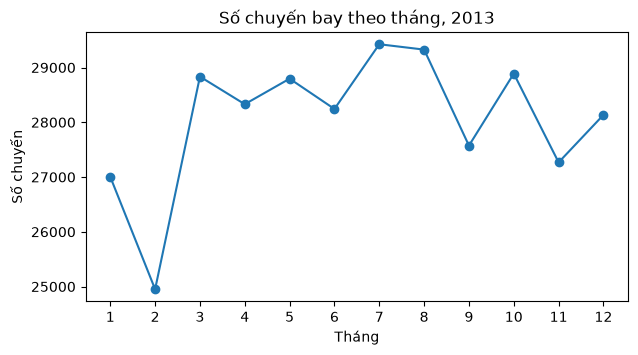

In [8]:
# số chuyến mỗi tháng
df.groupby('month').size().plot(marker='o', figsize=(7, 3.5))
plt.title('Số chuyến bay theo tháng, 2013')
plt.xlabel('Tháng')
plt.ylabel('Số chuyến')
plt.xticks(range(1, 13))
plt.show()

Ngày tháng hợp lệ (không có ngày không tồn tại, đủ 365 ngày) và dữ liệu phủ đủ 12 tháng.

### 1.2. Kiểm tra định dạng thời gian (HHMM)

In [9]:
time_cols = ['dep_time', 'sched_dep_time', 'arr_time', 'sched_arr_time']
time_checks = []

for col in time_cols:
    s = df[col].dropna()
    time_checks.append({
        'Cột thời gian': col,
        'Min': s.min(),
        'Max': s.max(),
        'Giờ >= 24': (s // 100 >= 24).sum(),
        'Phút >= 60': (s % 100 >= 60).sum()
    })

display(pd.DataFrame(time_checks))

,Cột thời gian,Min,Max,Giờ >= 24,Phút >= 60
0,dep_time,1.0,2400.0,29,0
1,sched_dep_time,106.0,2359.0,0,0
2,arr_time,1.0,2400.0,150,0
3,sched_arr_time,1.0,2359.0,0,0


Số phút hợp lệ 100%, xuất hiện các giá trị >= 24 (cụ thể là giá trị 2400) => cần được chuẩn hóa về 00:00 

#### 1.3. Kiểm tra tính nhất quán hãng bay và tuyến đường

In [10]:
# kiểm tra tính nhất quán giữa carrier và name
n_name_per_code = df.groupby('carrier')['name'].nunique()
n_code_per_name = df.groupby('name')['carrier'].nunique()
print('Mã hãng có nhiều hơn 1 tên :', int((n_name_per_code > 1).sum()))
print('Tên hãng có nhiều hơn 1 mã :', int((n_code_per_name > 1).sum()))
display(df.groupby(['carrier', 'name']).size().rename('n_flights')
          .reset_index().sort_values('n_flights', ascending=False).reset_index(drop=True))

Mã hãng có nhiều hơn 1 tên : 0
Tên hãng có nhiều hơn 1 mã : 0


,carrier,name,n_flights
0,UA,United Air Lines Inc.,58665
1,B6,JetBlue Airways,54635
2,EV,ExpressJet Airlines Inc.,54173
3,DL,Delta Air Lines Inc.,48110
4,AA,American Airlines Inc.,32729
5,MQ,Envoy Air,26397
6,US,US Airways Inc.,20536
7,9E,Endeavor Air Inc.,18460
8,WN,Southwest Airlines Co.,12275
9,VX,Virgin America,5162


Mỗi mã hãng gắn đúng một tên => không cần chuẩn hóa tên hãng.

In [11]:
# kiểm tra sân bay đi và đến
print('origin:', df['origin'].unique().tolist())
print('Số điểm đến (dest):', df['dest'].nunique())
# điểm đến không được là sân bay xuất phát
print('\nSố chuyến có dest nằm trong tập origin:', df['dest'].isin(df['origin']).sum())
display(df.loc[df['dest'].isin(df['origin']),
               ['month', 'day', 'sched_dep_time', 'dep_time', 'tailnum', 'carrier', 'flight', 'origin', 'dest', 'distance']])

origin: ['EWR', 'LGA', 'JFK']
Số điểm đến (dest): 105

Số chuyến có dest nằm trong tập origin: 1


,month,day,sched_dep_time,dep_time,tailnum,carrier,flight,origin,dest,distance
275945,7,27,106,NaN,NaN,US,1632,EWR,LGA,17


3 sân bay xuất phát và 105 sân bay đích. Có đúng 1 dòng bất thường EWR→LGA 17 dặm. Đây là chuyến hủy (không có giờ cất cánh, không có số đuôi)

In [12]:
# kiểm tra khoảng cách trên cùng tuyến bay
dist_route = df.groupby(['origin', 'dest'])['distance'].nunique()
print('\nSố tuyến có nhiều hơn 1 khoảng cách:', (dist_route > 1).sum())
# chi tiết các tuyến có khoảng cách không nhất quán
routes = dist_route[dist_route > 1].index
display( df.set_index(['origin', 'dest']).loc[routes].reset_index().groupby(['origin', 'dest', 'distance']).size().reset_index(name='n_flights'))


Số tuyến có nhiều hơn 1 khoảng cách: 2


,origin,dest,distance,n_flights
0,EWR,EGE,1725,51
1,EWR,EGE,1726,59
2,JFK,EGE,1746,44
3,JFK,EGE,1747,59


Kiểm tra tính nhất quán của biến distance cho thấy chỉ có 2 tuyến bay EWR–EGE và JFK–EGE xuất hiện hai giá trị khoảng cách, chênh lệch nhau 1 dặm.

#### 1.4. Kiểm tra dữ liệu bị thiếu

dep_time     8255
dep_delay    8255
arr_time     8713
arr_delay    9430
tailnum      2512
air_time     9430
dtype: int64


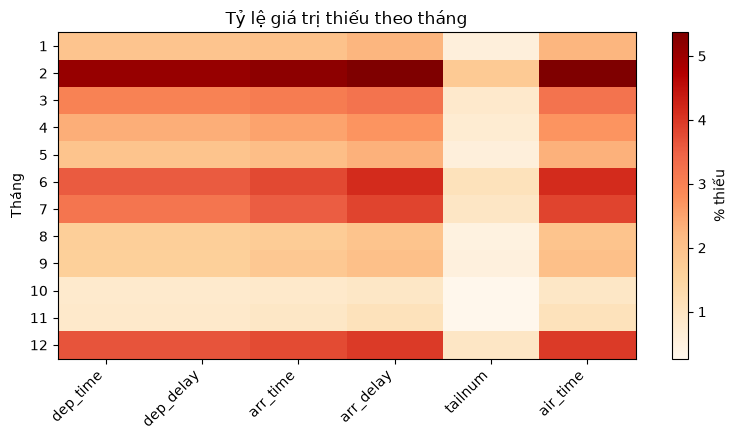

In [13]:
missing = df.isnull().sum()
missing_cols = missing[missing > 0]
cols_na = missing_cols.index
print(missing_cols)

# Heatmap: tỷ lệ thiếu (%) theo tháng 
miss_month = df[cols_na].isnull().groupby(df['month']).mean() * 100
fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(miss_month, aspect='auto', cmap='OrRd')
ax.set_xticks(range(len(cols_na)))
ax.set_xticklabels(cols_na, rotation=45, ha='right')
ax.set_yticks(range(12))
ax.set_yticklabels(range(1, 13))
ax.set_ylabel('Tháng')
fig.colorbar(im, label='% thiếu')
ax.set_title('Tỷ lệ giá trị thiếu theo tháng')
plt.tight_layout()
plt.show()

tỷ lệ thiếu phân bố không đều quanh năm xuất hiện các vệt màu đậm vào các tháng 2, 12, 6 và 7

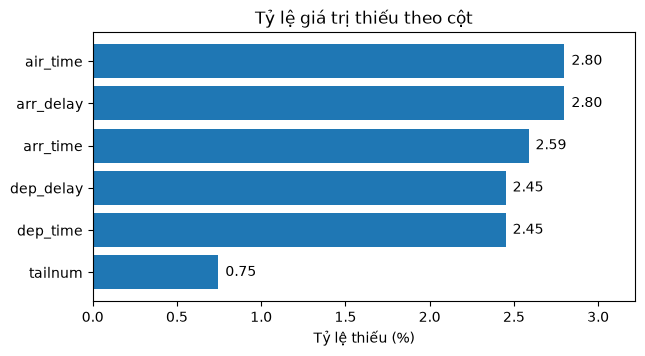

In [14]:
miss_pct = (df[cols_na].isnull().mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(miss_pct.index, miss_pct)
ax.bar_label(bars, fmt="%.2f", padding=5)
ax.set(title="Tỷ lệ giá trị thiếu theo cột", xlabel="Tỷ lệ thiếu (%)", xlim=(0, miss_pct.max() * 1.15))
plt.show()

tỷ lệ dữ liệu thiếu tương đối thấp (dưới 3%). Các cặp dep_time - dep_delay (2,45%) và arr_delay - air_time (2,80%) có tỷ lệ thiếu bằng nhau => dữ liệu thiếu có liên quan đến trạng thái vận hành chuyến bay. Vì vậy, thay vì xóa dòng hoặc điền mean, thì sẽ tạo các cờ trạng thái 

#### 1.5. kiểm tra dữ liệu trùng lặp

In [15]:
n_dup = df.drop(columns='id').duplicated().sum()
print('Số dòng trùng :', n_dup)

Số dòng trùng : 0


ko có dòng trùng => ko xóa dòng nào

#### 1.6. Khám phá giá trị ngoại lai

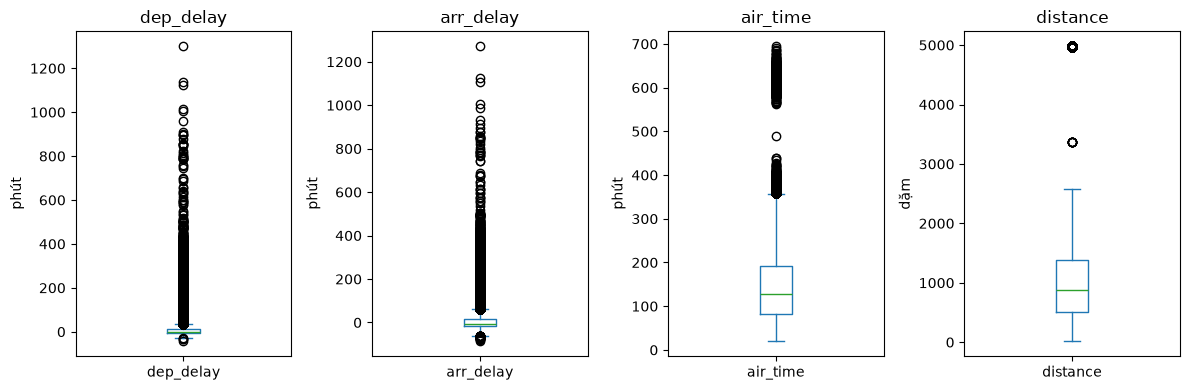

In [16]:
num_cols = ['dep_delay', 'arr_delay', 'air_time', 'distance']
units = {'dep_delay': 'phút', 'arr_delay': 'phút', 'air_time': 'phút', 'distance': 'dặm'}
fig, axes = plt.subplots(1, 4, figsize=(12, 4))
for ax, col in zip(axes, num_cols):
    df[col].plot.box(ax=ax)
    ax.set_title(col)
    ax.set_ylabel(units[col])
plt.tight_layout()
plt.show()

### Nhận xét:
- dep_delay và arr_delay: phần lớn giá trị tập trung trong khoảng tương đối hẹp, trong khi xuất hiện nhiều outlier ở phía giá trị lớn
- air_time: thời gian bay phân tán rộng hơn, xuất hiện các giá trị ngoại lai ở phía trên.
- distance: Khoảng cách bay có độ phân tán lớn, với một số giá trị cao vượt khỏi râu trên của Boxplot, cho thấy sự hiện diện của các chặng bay có cự ly lớn.

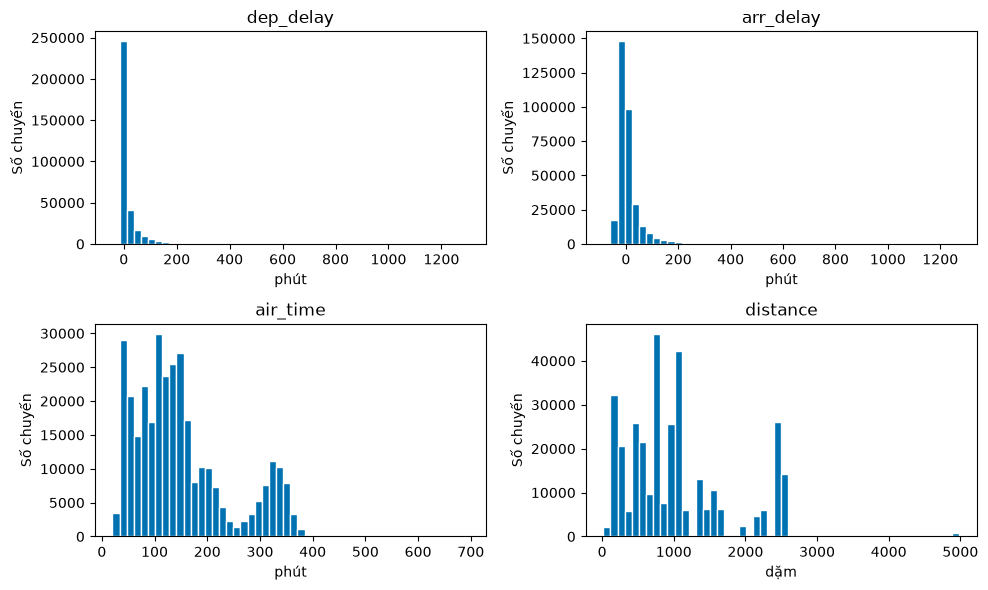

In [17]:
# Histogram cho 4 biến
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, col in zip(axes.ravel(), num_cols):
    ax.hist(df[col].dropna(), bins=50, color='#0072B2', edgecolor='white')
    ax.set_title(col)
    ax.set_xlabel(units[col])
    ax.set_ylabel('Số chuyến')

plt.tight_layout()
plt.show()

dữ liệu độ trễ chuyến bay có phân phối lệch với đuôi kéo dài, xuất hiện một số giá trị ngoại lai rất lớn. Vì vậy, biểu đồ được giới hạn trục hiển thị từ phân vị 1% đến 99%, giúp quan sát rõ hơn phân phối mà không loại bỏ các giá trị ngoại lai khỏi tập dữ liệu.

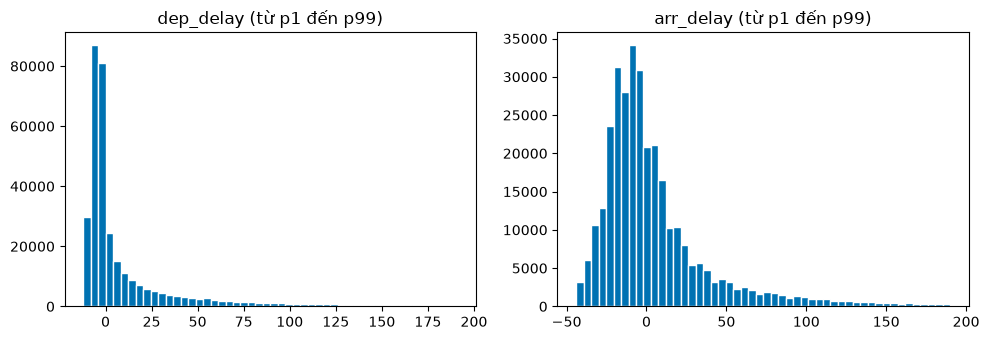

In [18]:
# vẽ lại 2 biến delay trong khoảng p1-p99
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(axes, ['dep_delay', 'arr_delay']):
    s = df[col].dropna()
    ax.hist(s, bins=50, range=(s.quantile(0.01), s.quantile(0.99)), color='#0072B2', edgecolor='white')
    ax.set_title(col + ' (từ p1 đến p99)')
plt.tight_layout()
plt.show()

khi phóng to vào p1–p99, phân phối lệch phải với đỉnh gần 0 là các chuyến đúng giờ hoặc đi sớm. Đây chỉ là cách hiển thị, không loại bỏ giá trị ngoại lai khỏi tập dữ liệu

In [19]:
# so sánh hai cách xác định "đuôi": IQR (1.5 x IQR) và phân vị p99
rows = {}
for col in num_cols:
    s = df[col].dropna()
    p99 = s.quantile(0.99)
    rows[col] = {
        'Độ lệch (skew)': s.skew(),
        'Median': s.median(),
        'p99': p99,
        'Max': s.max(),
        'Vượt p99 (%)': (s > p99).mean() * 100,
    }
tail_tbl = pd.DataFrame(rows).T.round(2)
display(tail_tbl)

# các chuyến trễ rất lớn có phải lỗi nhập liệu không? Nếu là sự cố thật thì trễ khi đi và trễ khi đến phải đi cùng nhau
x = df.loc[df['dep_delay'] > 300, ['dep_delay', 'arr_delay']].dropna()
print(f'\n{len(x)} chuyến trễ > 300 phút: tương quan dep_delay - arr_delay = {x["dep_delay"].corr(x["arr_delay"]):.3f}')

,Độ lệch (skew),Median,p99,Max,Vượt p99 (%)
dep_delay,4.80,-2.0,191.0,1301.0,0.99
arr_delay,3.72,-5.0,190.0,1272.0,0.99
air_time,1.07,129.0,364.0,695.0,1.00
distance,1.13,872.0,2586.0,4983.0,0.21



601 chuyến trễ > 300 phút: tương quan dep_delay - arr_delay = 0.985


In [20]:
rows = {}
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr 
    flagged = (df[col] < low) | (df[col] > high)
      
    rows[col] = {
        'Ngưỡng dưới': low,
        'Ngưỡng trên': high,
        'Số lượng outlier': flagged.sum(),
        'Tỷ lệ outlier (%)': flagged.sum() / df[col].count() * 100
    }
pd.DataFrame(rows).T.round(2)

,Ngưỡng dưới,Ngưỡng trên,Số lượng outlier,Tỷ lệ outlier (%)
dep_delay,-29.0,35.0,43216.0,13.15
arr_delay,-63.5,60.5,27880.0,8.52
air_time,-83.0,357.0,5448.0,1.66
distance,-828.5,2719.5,715.0,0.21


#### Tổng hợp các vấn đề từ EDA 
| Vấn đề phát hiện | Số liệu chứng minh | Định hướng xử lý |
|---|---|---|
|Mốc giờ 24:00|179 trường hợp giá trị 2400|Chuẩn hóa mốc 2400 về 0 (tương ứng 00:00)|
|Dữ liệu thiếu|	8.255 ô thiếu giờ bay, 9.430 ô thiếu giờ đến|Tạo 2 cờ nghiệp vụ is_cancelled và is_arrival_missing|
|Cột dư thừa| year (hằng số 2013), id (số thứ tự), minute (trùng)| Loại bỏ |
| Tuyến bất thường | 1 dòng bất thường ( điểm đến là sân đi), tuyến EGE có 2 khoảng cách | giữ và gắn cờ tuyến hiếm, thống nhất khoảng cách EGE |
| Đuôi trễ chuyến | vượt p99 gần 1% | Gắn cờ theo p99 thay vì xóa dòng |
| Chưa có thông tin điểm đến | dest chỉ là mã sân bay | thêm vùng |
|Nhu cầu phân tích|Chưa có thứ, mùa, tuyến, phân nhóm cự ly | Tạo các biến đặc trưng |

# Tiền xử lý 
#### 2.1. Xử lý dữ liệu thiếu bằng cờ nghiệp vụ

In [21]:
# tạo bản sao làm sạch
df_clean = df.copy()

In [22]:
df_clean['is_cancelled'] = df_clean['dep_time'].isna()     # không có giờ cất cánh có thể hiểu là chuyến hủy
df_clean['is_arrival_missing'] = df_clean['dep_time'].notna() & df_clean['arr_delay'].isna()   # đã có giờ cất cánh nhưng thiếu thông tin đến
df_clean[['is_cancelled', 'is_arrival_missing']].sum().to_frame('n_flights')

,n_flights
is_cancelled,8255
is_arrival_missing,1175


In [23]:
# kiểm tra số lượng ô thiếu chưa giải thích sau khi gắn cờ
df_valid = df_clean[~df_clean['is_cancelled'] & ~df_clean['is_arrival_missing']]

pd.DataFrame({
    'missing_trước': missing_cols,
    'missing_trước_%': (missing_cols / len(df_clean) * 100).round(2),
    'missing chưa giải thích': df_valid[cols_na].isnull().sum(),
})

,missing_trước,missing_trước_%,missing chưa giải thích
dep_time,8255,2.45,0
dep_delay,8255,2.45,0
arr_time,8713,2.59,0
arr_delay,9430,2.80,0
tailnum,2512,0.75,0
air_time,9430,2.80,0


#### 2.2. Chuẩn hóa mốc giờ 24:00 và tạo biến Datetime
Phục vụ: hướng thời gian giờ theo lịch dùng để đếm mật độ chuyến, giờ thực tế và giờ đến dùng khi cần.

In [24]:
n_2400 = (df_clean[time_cols] == 2400).sum().sum()
# Đổi 2400 -> 0 (00:00) cho cả 4 cột giờ
df_clean[time_cols] = df_clean[time_cols].replace(2400, 0)
print('Số giá trị 2400 trước khi chuẩn hóa:', n_2400, '\nSố giá trị còn sót lại:', (df_clean[time_cols] == 2400).sum().sum())

Số giá trị 2400 trước khi chuẩn hóa: 179 
Số giá trị còn sót lại: 0


In [25]:
# Ngày bay + giờ theo lịch -> datetime
date = pd.to_datetime(df_clean[['year', 'month', 'day']])
sched_min = df_clean['sched_dep_time'] // 100 * 60 + df_clean['sched_dep_time'] % 100
df_clean['sched_dep_datetime'] = date + pd.to_timedelta(sched_min, unit='min')
# Giờ khởi hành thực tế = giờ theo lịch + dep_delay (phút) (tự động sang ngày hôm sau khi qua nửa đêm)
df_clean['dep_datetime'] = df_clean['sched_dep_datetime'] + pd.to_timedelta(df_clean['dep_delay'], unit='min')
# Có bao nhiêu chuyến cất cánh sang ngày hôm sau so với lịch 
print('Số chuyến cất cánh sang ngày hôm sau:', (df_clean['dep_datetime'].dt.normalize() > date).sum())

Số chuyến cất cánh sang ngày hôm sau: 1236


In [26]:
# giờ đến (giờ địa phương nơi đến). Quy tắc: nếu giờ đồng hồ đến nhỏ hơn giờ đồng hồ đi thì chuyến đến sang ngày hôm sau
print('Số chuyến có arr_time < dep_time (trước khi xử lý):', (df['arr_time'] < df['dep_time']).sum())
arr_min = df_clean['arr_time'] // 100 * 60 + df_clean['arr_time'] % 100
dep_min = df_clean['dep_datetime'].dt.hour * 60 + df_clean['dep_datetime'].dt.minute
next_day = pd.to_timedelta((arr_min < dep_min).astype(int), unit='D')
df_clean['arr_datetime'] = df_clean['dep_datetime'].dt.normalize() + pd.to_timedelta(arr_min, unit='min') + next_day

# kiểm chứng: dựng giờ đến theo lịch bằng cùng quy tắc, chênh lệch với giờ đến thực tế phải đúng bằng arr_delay
sched_arr_min = df_clean['sched_arr_time'] // 100 * 60 + df_clean['sched_arr_time'] % 100
sched_dep_min = df_clean['sched_dep_datetime'].dt.hour * 60 + df_clean['sched_dep_datetime'].dt.minute
sched_next_day = pd.to_timedelta((sched_arr_min < sched_dep_min).astype(int), unit='D')
sched_arr_datetime = df_clean['sched_dep_datetime'].dt.normalize() + pd.to_timedelta(sched_arr_min, unit='min') + sched_next_day
has_delay = df_clean['arr_delay'].notna()
diff_min = (df_clean['arr_datetime'] - sched_arr_datetime).dt.total_seconds() / 60
print(f"Chênh lệch arr_datetime - giờ đến theo lịch trùng với arr_delay: {(diff_min == df_clean['arr_delay'])[has_delay].mean():.2%} ({has_delay.sum()} chuyến)")

# chuyến thiếu thông tin đến thì không dùng arr_datetime
df_clean.loc[df_clean['is_arrival_missing'], 'arr_datetime'] = pd.NaT
print('Số chuyến có arr_datetime:', df_clean['arr_datetime'].notna().sum())

Số chuyến có arr_time < dep_time (trước khi xử lý): 10633
Chênh lệch arr_datetime - giờ đến theo lịch trùng với arr_delay: 100.00% (327346 chuyến)
Số chuyến có arr_datetime: 327346


#### 2.3. Loại bỏ cột dư thừa và đổi tên cột

In [27]:
# kiểm tra trước khi loại bỏ
print('hour trùng với sched_dep_time // 100:', (df_clean['hour'] == df_clean['sched_dep_time'] // 100).all())
print('minute trùng với sched_dep_time % 100:', (df_clean['minute'] == df_clean['sched_dep_time'] % 100).all())
# loại bỏ 3 cột dư thừa
df_clean = df_clean.drop(columns=['id', 'year', 'minute'])

df_clean = df_clean.rename(columns={'name': 'carrier_name', 'hour': 'sched_dep_hour'})
df_clean['time_hour'] = pd.to_datetime(df_clean['time_hour'])
print('shape:', df_clean.shape)

hour trùng với sched_dep_time // 100: True
minute trùng với sched_dep_time % 100: True
shape: (336776, 23)


| Cột | Quyết định | Lý do |
|---|---|---|
| `id` | Bỏ | Chỉ là số thứ tự không mang giá trị thông tin |
| `year` | Bỏ | Hằng số 2013, đã nằm trong `sched_dep_datetime` |
| `hour` | Giữ, đổi tên `sched_dep_hour` | Là giờ khởi hành theo lịch, tên cũ dễ nhầm với giờ thực tế |
| `minute` | Bỏ | Đã nằm trong `sched_dep_time` và `sched_dep_datetime` |
| `time_hour` | Giữ, đổi sang datetime | Kết hợp với `origin` để nối dữ liệu thời tiết |
| `name` | Giữ, đổi tên `carrier_name` | Dùng làm nhãn hiển thị |

#### 2.4. Thống nhất khoảng cách của từng tuyến
Phục vụ: hướng không gian Mỗi tuyến chỉ có một khoảng cách để phân nhóm cự ly nhất quán.

In [28]:
# thống nhất khoảng cách mỗi tuyến về giá trị phổ biến nhất (chỉ tuyến EGE bị ảnh hưởng)
distance_before = df_clean['distance'].copy()
df_clean['distance'] = df_clean.groupby(['origin', 'dest'])['distance'].transform(lambda x: x.mode()[0])

print('Số dòng bị đổi khoảng cách:', (distance_before != df_clean['distance']).sum())
print('Số tuyến còn nhiều hơn 1 khoảng cách:', (df_clean.groupby(['origin', 'dest'])['distance'].nunique() > 1).sum())

Số dòng bị đổi khoảng cách: 95
Số tuyến còn nhiều hơn 1 khoảng cách: 0


#### 2.5. Gắn cờ đuôi trễ chuyến theo p99
Phục vụ: phân tích độ trễ Chỉ gắn cờ gần 1% chuyến trễ cực lớn để có thể xem phần thân phân phối khi cần, không xóa dòng nào.

In [29]:
for col in ['dep_delay', 'arr_delay']:
    p99 = df_clean[col].quantile(0.99)          # p99 tính trên các chuyến có dữ liệu
    df_clean['is_extreme_' + col] = df_clean[col] > p99
    n = df_clean['is_extreme_' + col].sum()
    print(f'{col}: p99 = {p99:.0f} phút -> {n} chuyến gắn cờ ({n / df_clean[col].notna().sum():.2%} số chuyến có dữ liệu)')

dep_delay: p99 = 191 phút -> 3268 chuyến gắn cờ (0.99% số chuyến có dữ liệu)
arr_delay: p99 = 190 phút -> 3254 chuyến gắn cờ (0.99% số chuyến có dữ liệu)


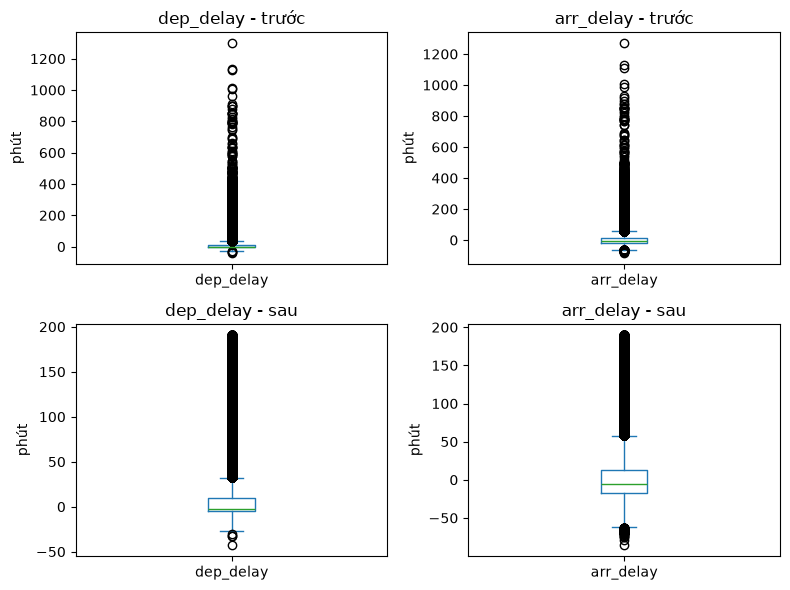

In [30]:
# so sánh trước và sau khi bỏ phần đuôi 
fig, axes = plt.subplots(2, 2, figsize=(8, 6))
for j, col in enumerate(['dep_delay', 'arr_delay']):
    df_clean[col].plot.box(ax=axes[0, j])      # trước: toàn bộ
    df_clean.loc[~df_clean['is_extreme_' + col], col].plot.box(ax=axes[1, j])      # sau: bỏ phần đuôi vượt p99
    axes[0, j].set_title(col + ' - trước')
    axes[1, j].set_title(col + ' - sau')
    axes[0, j].set_ylabel('phút')
    axes[1, j].set_ylabel('phút')
plt.tight_layout()
plt.show()

Sau khi bỏ  gần 1% chuyến vượt p99, giá trị lớn nhất của dep_delay và arr_delay giảm xuống, phần đuôi rất ít chuyến nhưng kéo giãn trục rất mạnh

#### 2.6. Tạo biến thời gian
| Biến | Lý do chọn |
|---|---|
| day_of_week | từ sched_dep_datetime để tạo biến định danh chu kỳ tuần |
| is_weekend | Quy ước thông thường về cuối tuần |
| season | Quy ước mùa theo khí tượng học (mỗi mùa 3 tháng) |
| time_of_date | Chia theo giờ theo lịch (sched_dep_hour): Sáng 5-10h, Trưa 11-13h, Chiều 14-17h, Tối 18-21h, Đêm 22-4h 
| week_of_year | Giữ hướng để biết tuyến đi hay về |
| dep_hour | giờ khỏi hành thực tế |

In [33]:
# 1. thứ trong tuần (0 = Thứ 2 ... 6 = CN) và cờ cuối tuần
df_clean['day_of_week'] = df_clean['sched_dep_datetime'].dt.dayofweek
df_clean['is_weekend'] = df_clean['day_of_week'] >= 5
# 2. tuần trong năm, gán lại tuần 53 cho 30-31/12
week = df_clean['sched_dep_datetime'].dt.isocalendar().week.astype(int)
df_clean['week_of_year'] = week.where(~((df_clean['month'] == 12) & (week == 1)), 53)
# 3. mùa trong năm 
season_map = {12: 'Đông', 1: 'Đông', 2: 'Đông', 3: 'Xuân', 4: 'Xuân', 5: 'Xuân',
              6: 'Hè', 7: 'Hè', 8: 'Hè', 9: 'Thu', 10: 'Thu', 11: 'Thu'}
df_clean['season'] = df_clean['month'].map(season_map)
# 4. giờ khởi hành thực tế và khung giờ trong ngày (theo giờ theo lịch)
df_clean['dep_hour'] = df_clean['dep_datetime'].dt.hour.astype('Int64')
h = df_clean['sched_dep_hour']
df_clean['time_of_day'] = np.select(
    [h.between(5, 10), h.between(11, 13), h.between(14, 17), h.between(18, 21)],
    ['Sáng', 'Trưa', 'Chiều', 'Tối'], default='Đêm')

print('Số tuần khác nhau:', df_clean['week_of_year'].nunique())
df_clean[['sched_dep_datetime', 'dep_datetime', 'sched_dep_hour', 'dep_hour', 'time_of_day', 'day_of_week',
          'is_weekend', 'week_of_year', 'season']].head()


Số tuần khác nhau: 53


,sched_dep_datetime,dep_datetime,sched_dep_hour,dep_hour,time_of_day,day_of_week,is_weekend,week_of_year,season
0,2013-01-01 05:15:00,2013-01-01 05:17:00,5,5,Sáng,1,False,1,Đông
1,2013-01-01 05:29:00,2013-01-01 05:33:00,5,5,Sáng,1,False,1,Đông
2,2013-01-01 05:40:00,2013-01-01 05:42:00,5,5,Sáng,1,False,1,Đông
3,2013-01-01 05:45:00,2013-01-01 05:44:00,5,5,Sáng,1,False,1,Đông
4,2013-01-01 06:00:00,2013-01-01 05:54:00,6,5,Sáng,1,False,1,Đông


#### 2.7. Tạo biến không gian
Phục vụ: hướng không gian Tuyến phổ biến, độ tin cậy của tuyến, nhóm cự ly và nhóm điểm đến

| Biến | Cách tạo |
|---|---|
| `route` | `origin-dest`: tuyến **đi** từ New York đến điểm đến (không có chiều về) |
| `route_count`, `is_rare_route` | Số chuyến của tuyến; tuyến hiếm = dưới 50 chuyến cả năm (chưa tới 1 chuyến/tuần, 50/52 tuần). Chỉ gắn cờ, chưa kết luận |
| `distance_group` | Dặm: Ngắn < 800, Trung bình 800–1.999, Dài >= 2.000 |

In [34]:
# 1. tuyến bay (từ New York đến điểm đến)
df_clean['route'] = df_clean['origin'] + '-' + df_clean['dest']
df_clean['route_count'] = df_clean.groupby('route')['route'].transform('size')
df_clean['is_rare_route'] = df_clean['route_count'] < 50
# 2. nhóm cự ly (dặm)
df_clean['distance_group'] = pd.cut(df_clean['distance'], bins=[0, 800, 2000, np.inf], right=False,
                              labels=['Ngắn', 'Trung bình', 'Dài'])

print('Số tuyến:', df_clean['route'].nunique(), '| số tuyến hiếm (< 50 chuyến):', df_clean.loc[df_clean['is_rare_route'], 'route'].nunique(),
      '| số chuyến thuộc tuyến hiếm:', df_clean['is_rare_route'].sum())

Số tuyến: 224 | số tuyến hiếm (< 50 chuyến): 23 | số chuyến thuộc tuyến hiếm: 355


#### 2.8. Chuẩn hóa kiểu dữ liệu

- Biến có thứ tự (season, time_of_day, distance_group): category có thứ tự.
- Biến danh nghĩa (origin, dest, route, carrier): category không có thứ tự.
- Các cột ngày giờ: datetime.

In [38]:
# category có thứ tự
df_clean['season'] = pd.Categorical(df_clean['season'], categories=['Xuân', 'Hè', 'Thu', 'Đông'], ordered=True)
df_clean['time_of_day'] = pd.Categorical(df_clean['time_of_day'], categories=['Sáng', 'Trưa', 'Chiều', 'Tối', 'Đêm'], ordered=True)
# distance_group đã là category có thứ tự (Ngắn < Trung bình < Dài) nhờ pd.cut

# category không thứ tự
for col in ['origin', 'dest', 'route', 'carrier']:
    df_clean[col] = df_clean[col].astype('category')

# kiểm tra khả năng gộp nhóm theo cặp biến (chỉ kiểm tra, chưa phân tích)
pd.crosstab(df_clean['time_of_day'], df_clean['season'])

season,Xuân,Hè,Thu,Đông
time_of_day,,,,
Sáng,29025,29646,28917,27399
Trưa,13713,13870,13791,12796
Chiều,23615,24095,23005,22307
Tối,18662,18300,17246,16688
Đêm,945,1084,772,900


#### Tổng kết trước và sau tiền xử lý

In [49]:
pd.DataFrame([
    ('Số dòng',                         len(df),                        len(df_clean)),
    ('Số cột',                          df.shape[1],                    df_clean.shape[1]),
    ('Số ô thiếu (cột gốc)',            df.isnull().sum().sum(),        df_clean[cols_na].isnull().sum().sum()),
    ('Số ô thiếu chưa giải thích',      df.isnull().sum().sum(),        df_valid[cols_na].isnull().sum().sum()),
    ('Dòng trùng',                      n_dup,                              0),
    ('Giá trị giờ = 2400',              n_2400,                             (df_clean[time_cols] == 2400).sum().sum()),
    ('Tuyến có nhiều hơn 1 khoảng cách',(df.groupby(['origin', 'dest'], observed=True)['distance'].nunique() > 1).sum(),(df_clean.groupby(['origin', 'dest'], observed=True)['distance'].nunique() > 1).sum()),
    ('Chuyến gắn cờ đuôi trễ: dep_delay (> p99)', 0,                                df_clean['is_extreme_dep_delay'].sum()),
    ('Chuyến gắn cờ đuôi trễ: arr_delay (> p99)', 0,                                df_clean['is_extreme_arr_delay'].sum()),
    ('Chuyến thuộc tuyến hiếm (< 50 chuyến)',     0,                                df_clean['is_rare_route'].sum()),
    ('Chuyến có arr_datetime',                    0,                                df_clean['arr_datetime'].notna().sum()),
    ], columns=['Chỉ tiêu', 'EDA', 'Sau chuẩn hóa'])

,Chỉ tiêu,EDA,Sau chuẩn hóa
0,Số dòng,336776,336776
1,Số cột,21,35
2,Số ô thiếu (cột gốc),46595,46595
3,Số ô thiếu chưa giải thích,46595,0
4,Dòng trùng,0,0
5,Giá trị giờ = 2400,179,0
6,Tuyến có nhiều hơn 1 khoảng cách,2,0
7,Chuyến gắn cờ đuôi trễ: dep_delay (> p99),0,3268
8,Chuyến gắn cờ đuôi trễ: arr_delay (> p99),0,3254
9,Chuyến thuộc tuyến hiếm (< 50 chuyến),0,355


#### Bảng mô tả cột mới

In [48]:
data_dictionary = pd.DataFrame([
    ('is_cancelled',         'Chuyến không có giờ cất cánh (hiểu là chuyến hủy)',        'dep_time bị thiếu'),
    ('is_arrival_missing',   'Đã cất cánh nhưng thiếu thông tin đến',                    'có dep_time nhưng thiếu arr_delay'),
    ('sched_dep_datetime',   'Giờ khởi hành THEO LỊCH (ngày + giờ)',                     'ngày bay + sched_dep_time'),
    ('dep_datetime',         'Giờ khởi hành THỰC TẾ',                                    'sched_dep_datetime + dep_delay (phút)'),
    ('arr_datetime',         'Giờ đến theo giờ địa phương nơi đến',                      'quy tắc sang ngày hôm sau khi giờ đến < giờ đi; NaT nếu hủy/thiếu thông tin đến'),
    ('sched_dep_hour',       'Giờ (0-23) khởi hành theo lịch (đổi tên từ hour)',         'cột hour gốc'),
    ('dep_hour',             'Giờ (0-23) khởi hành thực tế',                             'dep_datetime.hour; NaN nếu hủy'),
    ('time_of_day',          'Khung giờ trong ngày (category có thứ tự)',                'từ sched_dep_hour: Sáng 5-10, Trưa 11-13, Chiều 14-17, Tối 18-21, Đêm 22-4'),
    ('day_of_week',          'Thứ trong tuần (0 = Thứ 2 ... 6 = CN)',                    'ngày bay theo lịch .dayofweek'),
    ('is_weekend',           'Cờ cuối tuần',                                             'day_of_week >= 5 (Thứ 7, CN)'),
    ('week_of_year',         'Tuần trong năm (1-53)',                                    'tuần ISO; 30-31/12 gán 53'),
    ('season',               'Mùa (category có thứ tự)',                                 'từ month: Xuân 3-5, Hè 6-8, Thu 9-11, Đông 12-2'),
    ('route',                'Tuyến đi từ New York đến điểm đến',                        'origin + "-" + dest'),
    ('route_count',          'Số chuyến của tuyến trong năm',                            'đếm số dòng theo route'),
    ('is_rare_route',        'Cờ tuyến hiếm',                                            'route_count < 50'),
    ('distance_group',       'Nhóm cự ly (category có thứ tự)',                          'distance (dặm): Ngắn < 800, Trung bình 800-1999, Dài >= 2000'),
    ('is_extreme_dep_delay', 'Đuôi trễ khi cất cánh',                                    'dep_delay > p99 (191 phút)'),
    ('is_extreme_arr_delay', 'Đuôi trễ khi đến',                                         'arr_delay > p99 (190 phút)'),
    ('carrier_name',         'Tên hãng bay (đổi tên từ name)',                           'cột name gốc'),
    ('distance',             'Khoảng cách (dặm), đã thống nhất theo tuyến',              'giá trị phổ biến nhất của mỗi cặp origin-dest'),
], columns=['Cột', 'Ý nghĩa', 'Cách tính'])
data_dictionary

,Cột,Ý nghĩa,Cách tính
0,is_cancelled,Chuyến không có giờ cất cánh (hiểu là chuyến hủy),dep_time bị thiếu
1,is_arrival_missing,Đã cất cánh nhưng thiếu thông tin đến,có dep_time nhưng thiếu arr_delay
2,sched_dep_datetime,Giờ khởi hành THEO LỊCH (ngày + giờ),ngày bay + sched_dep_time
3,dep_datetime,Giờ khởi hành THỰC TẾ,sched_dep_datetime + dep_delay (phút)
4,arr_datetime,Giờ đến theo giờ địa phương nơi đến,quy tắc sang ngày hôm sau khi giờ đến < giờ đi...
5,sched_dep_hour,Giờ (0-23) khởi hành theo lịch (đổi tên từ hour),cột hour gốc
6,dep_hour,Giờ (0-23) khởi hành thực tế,dep_datetime.hour; NaN nếu hủy
7,time_of_day,Khung giờ trong ngày (category có thứ tự),"từ sched_dep_hour: Sáng 5-10, Trưa 11-13, Chiề..."
8,day_of_week,Thứ trong tuần (0 = Thứ 2 ... 6 = CN),ngày bay theo lịch .dayofweek
9,is_weekend,Cờ cuối tuần,"day_of_week >= 5 (Thứ 7, CN)"


In [50]:
# xuất file mới
output_path = "flights_clean.csv"
df_clean.to_csv(output_path, index=False, encoding="utf-8-sig")